# DSCI 552 — Homework 4

**Name:** Yangrong Lan  
**USC ID:** 5561147067  
**GitHub:** CallistoAma

This notebook follows the supplied Homework 4 template. The Homework 3 feature-extraction code is included only because it is required by Homework 4; the Homework 3 confidence-interval analysis is not repeated.

## 1. Data preparation (reused from Homework 3)

In [1]:
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.base import clone
from sklearn.compose import make_column_transformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
import statsmodels.api as sm

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Inconsistent values: penalty.*")
warnings.filterwarnings("ignore", message="The least populated class.*")
RANDOM_STATE = 552
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_rows", 30)
pd.set_option("display.max_columns", 12)

In [2]:
DATA_ROOT = Path("AReM/AReM")
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
SIGNALS = [f"series_{i}" for i in range(1, 7)]

def read_instance(path):
    rows = []
    for raw in path.read_text(encoding="utf-8", errors="replace").splitlines():
        line = raw.strip()
        if not line or line.startswith("#"):
            continue
        parts = line.rstrip(",").split(",") if "," in line else line.split()
        if len(parts) != 7:
            raise ValueError(f"Unexpected row in {path}: {line}")
        rows.append([float(x) for x in parts])
    return pd.DataFrame(rows, columns=["time", *SIGNALS])

def dataset_number(path):
    return int(re.search(r"(\d+)$", path.stem).group(1))

records = []
for activity in ACTIVITIES:
    for path in sorted((DATA_ROOT / activity).glob("dataset*.csv"), key=dataset_number):
        n = dataset_number(path)
        is_test = n in ({1, 2} if activity.startswith("bending") else {1, 2, 3})
        records.append({"activity": activity, "dataset": n, "split": "test" if is_test else "train",
                        "path": path, "frame": read_instance(path)})

meta = pd.DataFrame([{k: v for k, v in r.items() if k != "frame"} | {"rows": len(r["frame"])} for r in records])
display(meta.groupby(["split", "activity"]).size().unstack(fill_value=0))
print(f"Loaded {len(records)} instances: {(meta.split=='train').sum()} train and {(meta.split=='test').sum()} test.")

activity,bending1,bending2,cycling,lying,sitting,standing,walking
split,,,,,,,
test,2,2,3,3,3,3,3
train,5,4,12,12,12,12,12


Loaded 88 instances: 69 train and 19 test.


In [3]:
FEATURES = ("mean", "std", "max")
feature_cache = {}

def make_features(l, split):
    key = (l, split)
    if key in feature_cache:
        return feature_cache[key]
    rows, labels = [], []
    selected = [r for r in records if r["split"] == split]
    for r in selected:
        values = []
        for part_no, idx in enumerate(np.array_split(np.arange(len(r["frame"])), l), start=1):
            seg = r["frame"].iloc[idx]
            for signal in SIGNALS:
                s = seg[signal]
                values.extend([s.mean(), s.std(ddof=1), s.max()])
        columns = [f"part{part}_{signal}_{stat}" for part in range(1, l+1)
                   for signal in SIGNALS for stat in FEATURES]
        rows.append(values)
        labels.append(r["activity"])
    X = pd.DataFrame(rows, columns=columns)
    y_multi = pd.Series(labels, name="activity")
    y_binary = y_multi.str.startswith("bending").astype(int).rename("bending")
    feature_cache[key] = (X, y_binary, y_multi)
    return feature_cache[key]

X_train_1, y_train_bin, y_train_multi = make_features(1, "train")
X_test_1, y_test_bin, y_test_multi = make_features(1, "test")
print("Unsegmented feature matrices:", X_train_1.shape, X_test_1.shape)
print("Binary training class counts:", y_train_bin.value_counts().sort_index().to_dict())

Unsegmented feature matrices: (69, 18) (19, 18)
Binary training class counts: {0: 60, 1: 9}


## 2. Classification

### 2(a)(i) Binary-class scatter plots

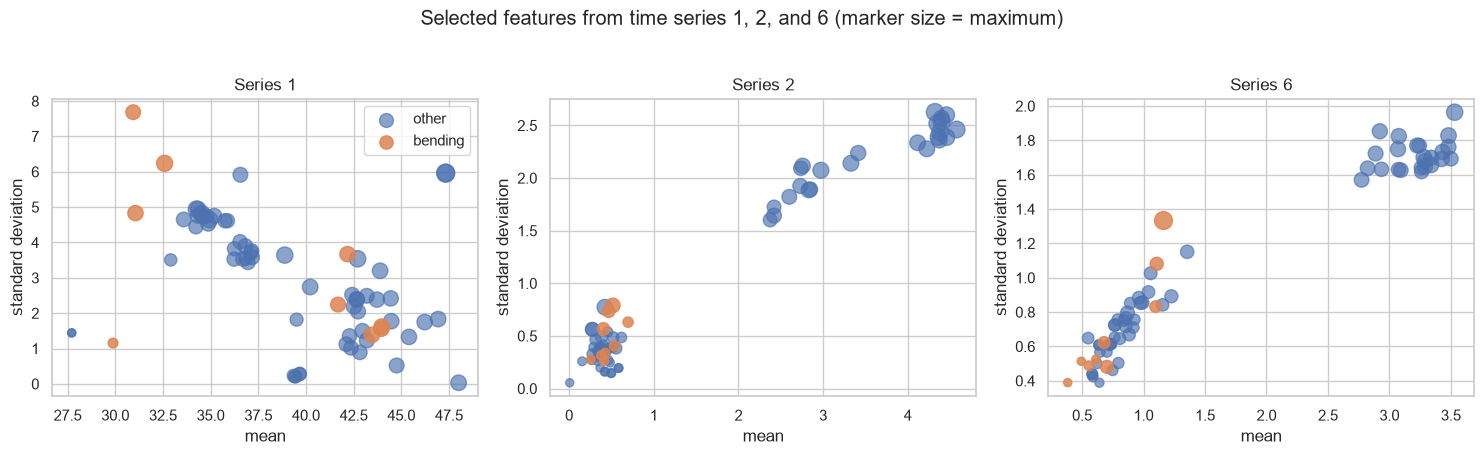

In [4]:
# Each panel displays all three chosen statistics: mean on x, standard deviation on y,
# and maximum as marker size. Color denotes bending versus other activities.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, s in zip(axes, (1, 2, 6)):
    mean = X_train_1[f"part1_series_{s}_mean"]
    std = X_train_1[f"part1_series_{s}_std"]
    maximum = X_train_1[f"part1_series_{s}_max"]
    sizes = 35 + 130 * (maximum - maximum.min()) / (maximum.max() - maximum.min() + 1e-12)
    ax.scatter(mean[y_train_bin==0], std[y_train_bin==0], s=sizes[y_train_bin==0], alpha=.65, label="other")
    ax.scatter(mean[y_train_bin==1], std[y_train_bin==1], s=sizes[y_train_bin==1], alpha=.85, label="bending")
    ax.set(title=f"Series {s}", xlabel="mean", ylabel="standard deviation")
axes[0].legend()
fig.suptitle("Selected features from time series 1, 2, and 6 (marker size = maximum)", y=1.03)
plt.tight_layout(); plt.show()

The classes overlap in some projections, but bending observations occupy noticeably different regions, especially for series 1 and 2. The maximum also adds information not contained in mean and standard deviation alone.

### 2(a)(ii) Split each series into two parts

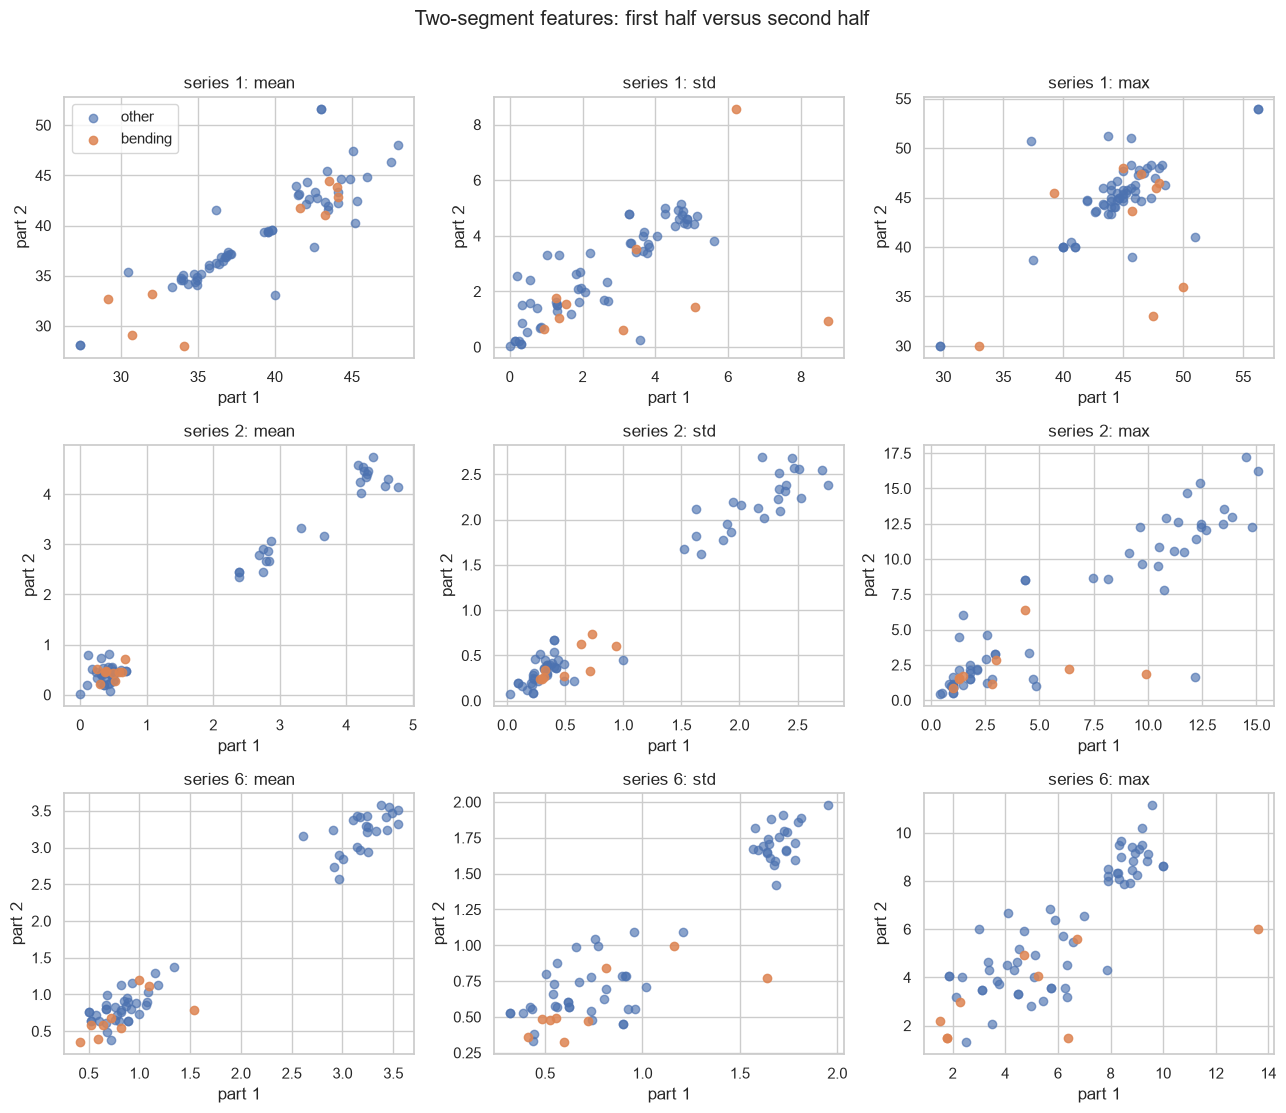

In [5]:
X_train_2, y2, _ = make_features(2, "train")
fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for row, s in enumerate((1, 2, 6)):
    for col, stat in enumerate(FEATURES):
        ax = axes[row, col]
        x = X_train_2[f"part1_series_{s}_{stat}"]
        y = X_train_2[f"part2_series_{s}_{stat}"]
        ax.scatter(x[y2==0], y[y2==0], alpha=.65, label="other")
        ax.scatter(x[y2==1], y[y2==1], alpha=.85, label="bending")
        ax.set(title=f"series {s}: {stat}", xlabel="part 1", ylabel="part 2")
axes[0,0].legend()
fig.suptitle("Two-segment features: first half versus second half", y=1.01)
plt.tight_layout(); plt.show()

Splitting exposes changes over time that a single whole-series statistic averages away. It can improve separation, but it also multiplies the number of predictors and therefore increases variance; cross-validation is needed to decide whether the extra resolution is useful.

### 2(a)(iii) Select the number of segments and features with stratified 5-fold CV

In [6]:
binary_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def candidate_feature_counts(q):
    base = [1, 2, 3, 5, 8, 12, 18, 25, 36, 54]
    return sorted(set(min(q, p) for p in base))

binary_search_rows = []
binary_searches = {}
for l in range(1, 21):
    X, y, _ = make_features(l, "train")
    base_lr = LogisticRegression(C=1e4, solver="liblinear", max_iter=5000, random_state=RANDOM_STATE)
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("rfe", RFE(base_lr, step=max(1, X.shape[1]//12))),
        ("logit", LogisticRegression(C=1e4, solver="liblinear", max_iter=5000, random_state=RANDOM_STATE)),
    ])
    search = GridSearchCV(pipe, {"rfe__n_features_to_select": candidate_feature_counts(X.shape[1])},
                          cv=binary_cv, scoring="accuracy", n_jobs=-1)
    search.fit(X, y)
    binary_searches[l] = search
    binary_search_rows.append({"l": l,
        "p": search.best_params_["rfe__n_features_to_select"],
        "cv_accuracy": search.best_score_})

binary_cv_results = pd.DataFrame(binary_search_rows)
display(binary_cv_results.style.format({"cv_accuracy": "{:.3f}"}))
best_binary_row = binary_cv_results.sort_values(["cv_accuracy", "p", "l"], ascending=[False, True, True]).iloc[0]
best_l = int(best_binary_row.l)
best_p = int(best_binary_row.p)
best_binary = binary_searches[best_l].best_estimator_
print(f"Chosen pair: l={best_l}, p={best_p}; mean stratified CV accuracy={best_binary_row.cv_accuracy:.3f}")

,l,p,cv_accuracy
0,1,1,0.943
1,2,1,0.943
2,3,1,0.971
3,4,1,0.943
4,5,1,0.957
5,6,18,0.957
6,7,12,0.957
7,8,12,0.971
8,9,8,0.929
9,10,3,0.957


Chosen pair: l=12, p=3; mean stratified CV accuracy=0.986


The feature selector is inside the pipeline passed to `GridSearchCV`, so feature selection is repeated using only the training portion of every fold. This is the correct procedure. Selecting features once on the complete training set and then cross-validating the already-selected columns would leak information from each validation fold and give an optimistically biased score. Stratification is important because bending is the minority class.

### 2(a)(iv) Final training fit, confusion matrix, ROC/AUC, coefficients, and p-values

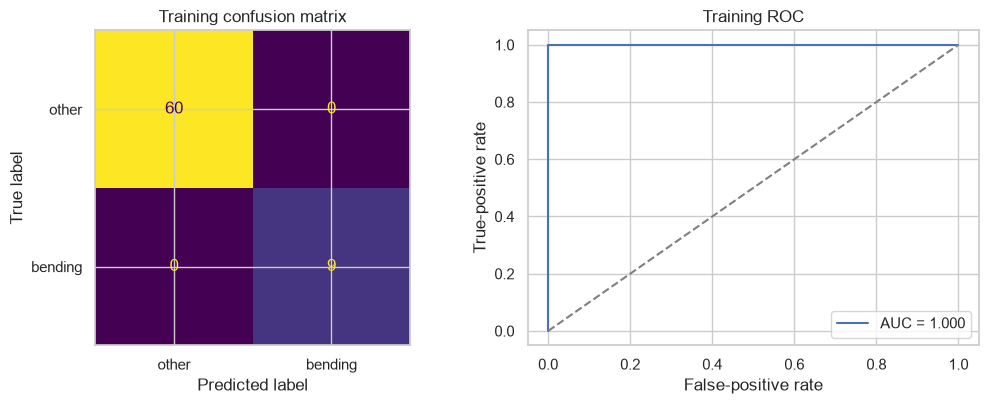

D:\Software\Anaconda\envs\dsci552\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
D:\Software\Anaconda\envs\dsci552\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


,coefficient,p_value
intercept,-132.8,0.9986
part2_series_5_mean,147.4,0.9986
part8_series_1_max,-36.88,0.9995
part10_series_1_std,36.32,0.9988


Training accuracy=1.000; AUC=1.000


In [7]:
X_train_best, y_train_bin, _ = make_features(best_l, "train")
X_test_best, y_test_bin, _ = make_features(best_l, "test")
best_binary.fit(X_train_best, y_train_bin)
support = best_binary.named_steps["rfe"].support_
selected_names = X_train_best.columns[support]

train_prob = best_binary.predict_proba(X_train_best)[:, 1]
train_pred = (train_prob >= .5).astype(int)
cm_train = confusion_matrix(y_train_bin, train_pred)
train_auc = roc_auc_score(y_train_bin, train_prob)
fpr, tpr, _ = roc_curve(y_train_bin, train_prob)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
ConfusionMatrixDisplay(cm_train, display_labels=["other", "bending"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Training confusion matrix")
axes[1].plot(fpr, tpr, label=f"AUC = {train_auc:.3f}")
axes[1].plot([0,1], [0,1], "--", color="gray")
axes[1].set(xlabel="False-positive rate", ylabel="True-positive rate", title="Training ROC")
axes[1].legend(); plt.tight_layout(); plt.show()

# Statsmodels is fitted on exactly the RFE-selected, standardized predictors.
Z = best_binary.named_steps["scale"].transform(X_train_best)
Zsel = Z[:, support]
try:
    inferential_fit = sm.GLM(y_train_bin.to_numpy(), sm.add_constant(Zsel), family=sm.families.Binomial()).fit()
    coef_table = pd.DataFrame({"coefficient": inferential_fit.params,
                               "p_value": inferential_fit.pvalues},
                              index=["intercept", *selected_names])
except Exception as exc:
    coef_table = pd.DataFrame({"coefficient": [np.nan], "p_value": [np.nan]}, index=["fit failed"])
    print("Unpenalized inferential fit warning:", exc)
display(coef_table.style.format({"coefficient": "{:.4g}", "p_value": "{:.4g}"}))
print(f"Training accuracy={accuracy_score(y_train_bin, train_pred):.3f}; AUC={train_auc:.3f}")

The coefficient table reports the requested unpenalized estimates and p-values on standardized selected predictors. If the separation diagnostic below is positive, maximum-likelihood estimates diverge and these Wald p-values are not reliable; that limitation is part of the model diagnosis.

### 2(a)(v) Test the classifier

In [8]:
test_prob = best_binary.predict_proba(X_test_best)[:, 1]
test_pred = (test_prob >= .5).astype(int)
cm_test = confusion_matrix(y_test_bin, test_pred)
test_acc = accuracy_score(y_test_bin, test_pred)
test_auc = roc_auc_score(y_test_bin, test_prob)
display(pd.DataFrame(cm_test, index=["actual other", "actual bending"],
                     columns=["predicted other", "predicted bending"]))
print(f"CV accuracy={best_binary_row.cv_accuracy:.3f}; test accuracy={test_acc:.3f}; test AUC={test_auc:.3f}")
print(f"Test minus CV accuracy = {test_acc-best_binary_row.cv_accuracy:+.3f}")

,predicted other,predicted bending
actual other,15,0
actual bending,1,3


CV accuracy=0.986; test accuracy=0.947; test AUC=0.967
Test minus CV accuracy = -0.038


### 2(a)(vi) Separation

In [9]:
coef_abs_max = np.abs(best_binary.named_steps["logit"].coef_).max()
perfect_train = (train_pred == y_train_bin).all()
print(f"Perfect training classification: {perfect_train}; largest absolute standardized coefficient: {coef_abs_max:.2f}")
if perfect_train and coef_abs_max > 10:
    print("The evidence is consistent with (quasi-)complete separation: the training classes are perfectly separated and coefficients are large.")
else:
    print("There is no strong evidence of complete separation under this diagnostic; errors remain or coefficients are not extreme.")

Perfect training classification: True; largest absolute standardized coefficient: 31.21
The evidence is consistent with (quasi-)complete separation: the training classes are perfectly separated and coefficients are large.


### 2(a)(vii) Class imbalance and case-control sampling

Training counts (other, bending): {0: 60, 1: 9} ; minority share = 0.13


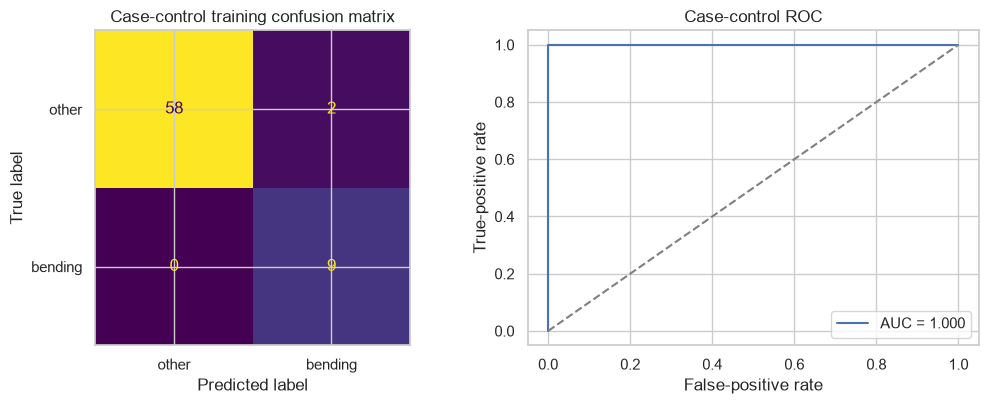

Intercept correction=-1.897; accuracy=0.971; AUC=1.000


In [10]:
counts = y_train_bin.value_counts().sort_index()
print("Training counts (other, bending):", counts.to_dict(), "; minority share =", round(y_train_bin.mean(), 3))

rng = np.random.default_rng(RANDOM_STATE)
case_idx = np.flatnonzero(y_train_bin.to_numpy() == 1)
control_idx = np.flatnonzero(y_train_bin.to_numpy() == 0)
sampled_control_idx = rng.choice(control_idx, size=len(case_idx), replace=False)
cc_idx = np.r_[case_idx, sampled_control_idx]

cc_model = clone(best_binary).fit(X_train_best.iloc[cc_idx], y_train_bin.iloc[cc_idx])
population_prior = y_train_bin.mean()
sample_prior = y_train_bin.iloc[cc_idx].mean()
intercept_adjustment = np.log(population_prior/(1-population_prior)) - np.log(sample_prior/(1-sample_prior))
cc_model.named_steps["logit"].intercept_ += intercept_adjustment

cc_prob = cc_model.predict_proba(X_train_best)[:,1]
cc_pred = (cc_prob >= .5).astype(int)
cc_cm = confusion_matrix(y_train_bin, cc_pred)
cc_auc = roc_auc_score(y_train_bin, cc_prob)
cc_fpr, cc_tpr, _ = roc_curve(y_train_bin, cc_prob)
fig, axes = plt.subplots(1,2,figsize=(10.5,4.2))
ConfusionMatrixDisplay(cc_cm, display_labels=["other","bending"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Case-control training confusion matrix")
axes[1].plot(cc_fpr, cc_tpr, label=f"AUC = {cc_auc:.3f}")
axes[1].plot([0,1],[0,1],"--",color="gray"); axes[1].legend()
axes[1].set(xlabel="False-positive rate", ylabel="True-positive rate", title="Case-control ROC")
plt.tight_layout(); plt.show()
print(f"Intercept correction={intercept_adjustment:.3f}; accuracy={accuracy_score(y_train_bin,cc_pred):.3f}; AUC={cc_auc:.3f}")

The data are imbalanced because bending has far fewer instances. Case-control sampling balances the fitting sample; the intercept correction restores the population prior. Slopes and ranking (hence AUC) are the main quantities preserved by this design.

### 2(b)(i) L1-penalized binary logistic regression

In [11]:
C_GRID = np.logspace(-3, 3, 9)
l1_binary_rows, l1_binary_searches = [], {}
for l in range(1, 21):
    X, y, _ = make_features(l, "train")
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("logit", LogisticRegression(l1_ratio=1.0, solver="liblinear", max_iter=5000,
                                      random_state=RANDOM_STATE))])
    search = GridSearchCV(pipe, {"logit__C": C_GRID}, cv=binary_cv,
                          scoring="accuracy", n_jobs=-1)
    search.fit(X, y)
    l1_binary_searches[l] = search
    l1_binary_rows.append({"l": l, "C": search.best_params_["logit__C"],
                           "cv_accuracy": search.best_score_})
l1_binary_results = pd.DataFrame(l1_binary_rows)
display(l1_binary_results.style.format({"C":"{:.4g}", "cv_accuracy":"{:.3f}"}))
l1_best_row = l1_binary_results.sort_values(["cv_accuracy","l"], ascending=[False,True]).iloc[0]
l1_l = int(l1_best_row.l)
l1_binary = l1_binary_searches[l1_l].best_estimator_
Xtr_l1, ytr_l1, _ = make_features(l1_l, "train")
Xte_l1, yte_l1, _ = make_features(l1_l, "test")
l1_binary.fit(Xtr_l1, ytr_l1)
l1_nonzero = int(np.count_nonzero(l1_binary.named_steps["logit"].coef_))
l1_test_acc = accuracy_score(yte_l1, l1_binary.predict(Xte_l1))
print(f"Chosen l={l1_l}, C={l1_best_row.C:.4g}, nonzero coefficients={l1_nonzero}, "
      f"CV accuracy={l1_best_row.cv_accuracy:.3f}, test accuracy={l1_test_acc:.3f}")

,l,C,cv_accuracy
0,1,0.1778,0.971
1,2,0.1778,0.957
2,3,1,0.957
3,4,1,0.957
4,5,1,0.929
5,6,1000,0.943
6,7,5.623,0.943
7,8,1,0.942
8,9,0.1778,0.913
9,10,1000,0.957


Chosen l=12, C=1, nonzero coefficients=5, CV accuracy=0.986, test accuracy=0.947


### 2(b)(ii) L1 versus RFE/p-value-style selection

In [12]:
comparison = pd.DataFrame([
    {"method":"RFE + logistic", "l":best_l, "selected_features":best_p,
     "cv_accuracy":best_binary_row.cv_accuracy, "test_accuracy":test_acc},
    {"method":"L1 logistic", "l":l1_l, "selected_features":l1_nonzero,
     "cv_accuracy":l1_best_row.cv_accuracy, "test_accuracy":l1_test_acc},
])
display(comparison.style.format({"cv_accuracy":"{:.3f}","test_accuracy":"{:.3f}"}))
winner = comparison.sort_values(["test_accuracy","selected_features"], ascending=[False,True]).iloc[0]
print(f"On the held-out test set, {winner.method} is preferable under accuracy (ties favor the sparser model).")

,method,l,selected_features,cv_accuracy,test_accuracy
0,RFE + logistic,12,3,0.986,0.947
1,L1 logistic,12,5,0.986,0.947


On the held-out test set, RFE + logistic is preferable under accuracy (ties favor the sparser model).


L1 performs selection and shrinkage simultaneously, while RFE makes a discrete subset choice and then fits the classifier. The held-out comparison above is more informative than training accuracy; with this small data set, small differences should not be over-interpreted.

### 2(c)(i) L1-penalized multinomial logistic regression

,l,C,cv_accuracy
0,1,1,0.899
1,2,177.8,0.900
2,3,177.8,0.899
3,4,5.623,0.886
4,5,177.8,0.899
5,6,1000,0.899
6,7,1000,0.855
7,8,1000,0.826
8,9,177.8,0.842
9,10,177.8,0.810


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,1,0,0,0,1,1,0
standing,0,0,0,1,0,2,0
walking,0,0,0,0,0,0,3


Chosen l=2, C=177.8; CV accuracy=0.900; test error=0.211


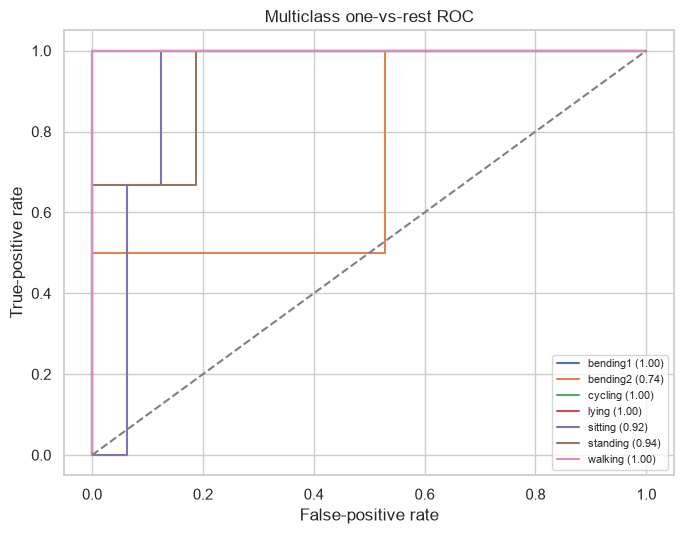

,class,ovr_auc
0,bending1,1.000
1,bending2,0.735
2,cycling,1.000
3,lying,1.000
4,sitting,0.917
5,standing,0.938
6,walking,1.000


In [13]:
multi_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
multi_rows, multi_searches = [], {}
for l in range(1, 21):
    X, _, y = make_features(l, "train")
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("logit", LogisticRegression(l1_ratio=1.0, solver="saga", max_iter=8000,
                                      random_state=RANDOM_STATE))])
    search = GridSearchCV(pipe, {"logit__C": C_GRID}, cv=multi_cv,
                          scoring="accuracy", n_jobs=-1)
    search.fit(X, y)
    multi_searches[l] = search
    multi_rows.append({"l":l, "C":search.best_params_["logit__C"],
                       "cv_accuracy":search.best_score_})
multi_results = pd.DataFrame(multi_rows)
display(multi_results.style.format({"C":"{:.4g}","cv_accuracy":"{:.3f}"}))
multi_best_row = multi_results.sort_values(["cv_accuracy","l"], ascending=[False,True]).iloc[0]
multi_l = int(multi_best_row.l)
multi_model = multi_searches[multi_l].best_estimator_
Xtr_m, _, ytr_m = make_features(multi_l, "train")
Xte_m, _, yte_m = make_features(multi_l, "test")
multi_model.fit(Xtr_m, ytr_m)
multi_pred = multi_model.predict(Xte_m)
multi_prob = multi_model.predict_proba(Xte_m)
classes = multi_model.classes_
multi_error = 1 - accuracy_score(yte_m, multi_pred)
display(pd.DataFrame(confusion_matrix(yte_m, multi_pred, labels=classes), index=classes, columns=classes))
print(f"Chosen l={multi_l}, C={multi_best_row.C:.4g}; CV accuracy={multi_best_row.cv_accuracy:.3f}; test error={multi_error:.3f}")

# One-vs-rest ROC curves and AUCs.
yte_bin = label_binarize(yte_m, classes=classes)
fig, ax = plt.subplots(figsize=(7,5.5))
auc_rows = []
for j, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(yte_bin[:,j], multi_prob[:,j])
    auc_j = roc_auc_score(yte_bin[:,j], multi_prob[:,j])
    auc_rows.append({"class":cls, "ovr_auc":auc_j})
    ax.plot(fpr,tpr,label=f"{cls} ({auc_j:.2f})")
ax.plot([0,1],[0,1],"--",color="gray")
ax.set(xlabel="False-positive rate",ylabel="True-positive rate",title="Multiclass one-vs-rest ROC")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
display(pd.DataFrame(auc_rows).style.format({"ovr_auc":"{:.3f}"}))

### 2(c)(ii) Gaussian and Multinomial Naive Bayes

In [14]:
nb_rows, nb_models = [], {}
for model_name, estimator in [("GaussianNB", GaussianNB()), ("MultinomialNB", MultinomialNB())]:
    for l in range(1, 21):
        X, _, y = make_features(l, "train")
        scores = cross_val_score(estimator, X, y, cv=multi_cv, scoring="accuracy", n_jobs=-1)
        nb_rows.append({"method":model_name,"l":l,"cv_accuracy":scores.mean()})
nb_results = pd.DataFrame(nb_rows)
display(nb_results.pivot(index="l",columns="method",values="cv_accuracy").style.format("{:.3f}"))

nb_test_rows = []
for model_name, estimator in [("GaussianNB", GaussianNB()), ("MultinomialNB", MultinomialNB())]:
    best = nb_results[nb_results.method==model_name].sort_values(["cv_accuracy","l"],ascending=[False,True]).iloc[0]
    l = int(best.l)
    Xtr, _, ytr = make_features(l,"train")
    Xte, _, yte = make_features(l,"test")
    fitted = clone(estimator).fit(Xtr,ytr)
    pred = fitted.predict(Xte)
    err = 1-accuracy_score(yte,pred)
    nb_models[model_name] = fitted
    nb_test_rows.append({"method":model_name,"l":l,"cv_accuracy":best.cv_accuracy,"test_error":err})
    print(f"\n{model_name} confusion matrix (l={l})")
    display(pd.DataFrame(confusion_matrix(yte,pred,labels=ACTIVITIES),index=ACTIVITIES,columns=ACTIVITIES))
nb_test_results = pd.DataFrame(nb_test_rows)
display(nb_test_results.style.format({"cv_accuracy":"{:.3f}","test_error":"{:.3f}"}))

method,GaussianNB,MultinomialNB
l,,
1,0.898,0.824
2,0.869,0.823
3,0.886,0.882
4,0.870,0.884
5,0.870,0.869
6,0.841,0.854
7,0.885,0.854
8,0.841,0.854
9,0.798,0.869



GaussianNB confusion matrix (l=1)


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,0,0,0,0,3,0,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3



MultinomialNB confusion matrix (l=4)


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,2,0,0,0,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,2,1,0,0
sitting,0,0,0,0,2,1,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


,method,l,cv_accuracy,test_error
0,GaussianNB,1,0.898,0.105
1,MultinomialNB,4,0.884,0.158


### 2(c)(iii) Multiclass comparison

In [15]:
all_multi = pd.concat([
    pd.DataFrame([{"method":"L1 multinomial logistic","l":multi_l,
                   "cv_accuracy":multi_best_row.cv_accuracy,"test_error":multi_error}]),
    nb_test_results
], ignore_index=True)
display(all_multi.style.format({"cv_accuracy":"{:.3f}","test_error":"{:.3f}"}))
best_multi = all_multi.sort_values(["test_error","cv_accuracy"],ascending=[True,False]).iloc[0]
print(f"Best held-out result: {best_multi.method} (test error {best_multi.test_error:.3f}).")

,method,l,cv_accuracy,test_error
0,L1 multinomial logistic,2,0.900,0.211
1,GaussianNB,1,0.898,0.105
2,MultinomialNB,4,0.884,0.158


Best held-out result: GaussianNB (test error 0.105).


The best method is chosen from held-out error, with CV accuracy used as a secondary diagnostic. Gaussian NB is flexible about feature signs but assumes conditional independence and class-specific univariate Gaussian distributions. Multinomial NB is designed for non-negative count-like features, so its assumptions are less natural for continuous time-domain statistics. L1 multinomial logistic regression is discriminative and can suppress redundant segmented features.

## 3. ISLR 4.8.3 — One-dimensional QDA

For class `k`, Bayes' rule assigns an observation to the class maximizing

`pi_k * (1 / sqrt(2*pi*sigma_k^2)) * exp(-(x-mu_k)^2 / (2*sigma_k^2))`.

Taking logarithms and discarding the common constant `-log(sqrt(2*pi))` gives the discriminant

`delta_k(x) = log(pi_k) - log(sigma_k) - (x-mu_k)^2/(2*sigma_k^2)`.

Expanding the square,

`delta_k(x) = -x^2/(2*sigma_k^2) + (mu_k/sigma_k^2)x - mu_k^2/(2*sigma_k^2) + log(pi_k) - log(sigma_k)`.

This is quadratic in `x`. For two classes `k` and `j`, the decision boundary solves `delta_k(x)=delta_j(x)`. Its `x^2` coefficient is

`(1/(2*sigma_j^2) - 1/(2*sigma_k^2))`,

which is generally nonzero when the class variances differ. Thus the boundary is quadratic. It becomes linear only in the special equal-variance case, which is exactly the LDA assumption.

## 4. ISLR 4.8.7 — Dividend probability

Let `Y=Yes` denote a dividend. The priors are `P(Yes)=0.8` and `P(No)=0.2`. The class-conditional distributions are normal with means 10 and 0 and common variance 36. At `x=4`, Bayes' rule gives

`P(Yes|X=4) = [0.8 exp(-(4-10)^2/72)] / [0.8 exp(-(4-10)^2/72) + 0.2 exp(-(4-0)^2/72)]`

`= [0.8 exp(-0.5)] / [0.8 exp(-0.5) + 0.2 exp(-2/9)] = 0.7519`.

Therefore, the predicted probability that the company issues a dividend is approximately **75.2%**, so the Bayes classifier predicts **Yes**.

## Reproducibility summary

In [16]:
print("Random state:", RANDOM_STATE)
print("Train/test instances:", (meta.split=="train").sum(), (meta.split=="test").sum())
print("Binary choice (l,p):", (best_l,best_p))
print("L1 binary choice (l,C):", (l1_l,float(l1_best_row.C)))
print("L1 multiclass choice (l,C):", (multi_l,float(multi_best_row.C)))

Random state: 552
Train/test instances: 69 19
Binary choice (l,p): (12, 3)
L1 binary choice (l,C): (12, 1.0)
L1 multiclass choice (l,C): (2, 177.82794100389228)
